# Business entity resolution: walkthrough

Amazon ML Challenge 2026 dataset. Three sources of business records (name, address, country). Source 1 is
deduplicated; for each Source 1 business, find every Source 2/3 record that is the same business.
Scored with entity-level F0.5 (precision counts twice as much as recall).

This notebook reads the Parquet files and the reports written by the pipeline (`run_all.sh`), so it runs in seconds.

In [1]:
import json, sys
from pathlib import Path
import duckdb, pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
PQ, REP = ROOT / "data" / "parquet", ROOT / "reports"
con = duckdb.connect()
pd.set_option("display.max_colwidth", 90)

## 1. The data

In [2]:
con.execute(f'''
SELECT split, src, country, count(*) records FROM (
  SELECT 'train' split, 'S1' src, country FROM '{PQ}/train_s1.parquet' UNION ALL
  SELECT 'train', 'S2', country FROM '{PQ}/train_s2.parquet' UNION ALL
  SELECT 'train', 'S3', country FROM '{PQ}/train_s3.parquet' UNION ALL
  SELECT 'test', 'S1', country FROM '{PQ}/test_s1.parquet' UNION ALL
  SELECT 'test', 'S2', country FROM '{PQ}/test_s2.parquet' UNION ALL
  SELECT 'test', 'S3', country FROM '{PQ}/test_s3.parquet')
GROUP BY ALL ORDER BY split DESC, src, country''').fetchdf().pivot_table(index=['split','src'], columns='country', values='records')

country      France      India         US
split src                                
test  S1   259452.0   809986.0   663106.0
      S2   703378.0  2312565.0  1871330.0
      S3   731615.0  2405000.0  1945701.0
train S1        NaN   883188.0  1323633.0
      S2        NaN  2017799.0  3016817.0
      S3        NaN  2115547.0  3170056.0

**Three facts from the labels that shape the whole design**

1. Each Source 2/3 record is matched to *at most one* Source 1 business, so a record can be assigned to its single best business.
2. Most businesses have several matches (3.5 on average), only ~5.6% have none, so predicting nothing is rarely right.
3. About a quarter of Source 2/3 records match nothing: they are near-duplicate distractors (same name, different house number or town).

In [3]:
con.execute(f'''CREATE OR REPLACE TABLE gt AS SELECT source1_entity_id s1, unnest(CASE WHEN matched_entity_ids IS NULL OR matched_entity_ids = ''
  THEN [NULL] ELSE string_split(matched_entity_ids, ',') END) m FROM '{PQ}/train_gt.parquet' ''')
per = con.execute("SELECT nm AS matches_per_business, count(*) businesses FROM (SELECT s1, count(m) nm FROM gt GROUP BY s1) GROUP BY 1 ORDER BY 1").fetchdf()
per['share'] = (per.businesses / per.businesses.sum()).round(4)
display(per)
print('records owned by more than one Source 1 business:',
      con.execute("SELECT count(*) FROM (SELECT m FROM gt WHERE m IS NOT NULL GROUP BY m HAVING count(DISTINCT s1) > 1)").fetchone()[0])

,matches_per_business,businesses,share
0,0,123247,0.0558
1,1,119157,0.0540
2,2,375212,0.1700
3,3,530841,0.2405
4,4,484115,0.2194
5,5,321957,0.1459
6,6,164868,0.0747
7,7,63968,0.0290
8,8,18680,0.0085
9,9,4205,0.0019


records owned by more than one Source 1 business: 0


## 2. What the noise looks like

In [4]:
con.execute(f'''
WITH pick AS (SELECT entity_id FROM '{PQ}/train_s1.parquet' WHERE country = 'India' USING SAMPLE 3 ROWS (reservoir, 5))
SELECT a.business_name s1_name, a.business_address s1_address, b.business_name match_name, b.business_address match_address
FROM pick JOIN '{PQ}/train_s1.parquet' a USING (entity_id) JOIN gt ON gt.s1 = a.entity_id
JOIN (SELECT * FROM '{PQ}/train_s2.parquet' UNION ALL SELECT * FROM '{PQ}/train_s3.parquet') b ON b.entity_id = gt.m''').fetchdf()

,s1_name,s1_address,match_name,match_address
0,South Projects Limited,"Bagalkot, Karnataka, H No 1255 3Rd Cross, Jamkhandi, Venkateshwar Colony",South Projects,"Door No 1255 3Rd Cross, Jamkhandi, KA"
1,South Projects Limited,"Bagalkot, Karnataka, H No 1255 3Rd Cross, Jamkhandi, Venkateshwar Colony",M/s South Limited Center,"Jamkhandi, KA, Bagalkot, H No 1255 3Rd Cross"
2,South Projects Limited,"Bagalkot, Karnataka, H No 1255 3Rd Cross, Jamkhandi, Venkateshwar Colony",ಸೌತ್ ಪ್ರಾಜೆಕ್ಟ್ಸ್ ಲಿಮಿಟೆಡ್,"3RD CROSS, BAGALKOT, Karnataka"
3,Sriperumbudur Bio LLP,"No. 2/407 First Cross Street, Ambedkar Nagar, Sriperumbudur, Kanchipuram, Tamil Nadu",Sriperumbudur LLP Bio,"2/407 First Cross Street, Ambedkar Nagar, Sriperumbudur, Mugalivakkam, தமிழ்நாடு"
4,Sriperumbudur Bio LLP,"No. 2/407 First Cross Street, Ambedkar Nagar, Sriperumbudur, Kanchipuram, Tamil Nadu",@SRIPERUMBUDURBIO,"NO. /407 FIRST CROSS STREET, AMBEDKAR NAGAR, SRIPERUMBUDUR, Tamil Nadu"
5,Sriperumbudur Bio LLP,"No. 2/407 First Cross Street, Ambedkar Nagar, Sriperumbudur, Kanchipuram, Tamil Nadu",Sriperumbudur Bio,"NO. /407 FIRST CROSS STREET, AMBEDKAR NAGAR, SRIPERUMBUDUR, Tamil Nadu"
6,Sriperumbudur Bio LLP,"No. 2/407 First Cross Street, Ambedkar Nagar, Sriperumbudur, Kanchipuram, Tamil Nadu",SRIPERUMBUDURBIO.COM,"DOOR NO /407 FIRST CROSS STREET, AMBEDKAR NAGAR, SRIPERUMBUDUR, Tamil Nadu"


## 3. Normalisation

Transliteration to ASCII, abbreviation tables, 'trading as' splitting, and a phonetic skeleton so that a name written
in an Indian script gets the same key as its English spelling.

In [5]:
from normalize import normalize_record
examples = [("Indian Care Private Limited", "Itwari Mohalla Shahdol, Shahdol, Madhya Pradesh"),
            ("इंडियन केयर प्राइवेट लिमिटेड", "#917/8 Itwari Mohalla Shahdol, Shahdol, Umaria, MP"),
            ("Nexjaxlyra trading as Indian Care Private Limited", "Itwari Mohalla Shahdol, Shahdol, Madhya Pradesh"),
            ("Montari Spíre", "#34184 Tanglewood Pass, SAN TAN Valley CITY, Arizona")]
pd.DataFrame([{"name": n, **normalize_record(n, a)} for n, a in examples])[["name", "name_core", "name_phon", "addr_words", "house_no"]]

,name,name_core,name_phon,addr_words,house_no
0,Indian Care Private Limited,indian care,intn sr,itwari mohalla shahdol shahdol mp,
1,इंडियन केयर प्राइवेट लिमिटेड,inddiyn keyr praaivett limittedd,intn sr,itwari mohalla shahdol shahdol umaria mp,917/8
2,Nexjaxlyra trading as Indian Care Private Limited,nexjaxlyra indian care,nscslr intn sr,itwari mohalla shahdol shahdol mp,
3,Montari Spíre,montari spire,mntr spr,tanglewood pass san tan valley az,34184


## 4. Blocking

Ten key families (name word, phonetic word, address word pair, name+address word, whole name, name without spaces,
name/address word + house number). A key is used only if at most 200 (whole-name keys: 1,000) target records carry it.
Candidates are ranked by the summed IDF of shared keys and the top 40 per business are kept.

,top_k,pairs,pairs_per_s1,pair_recall,ceiling_f05,reduction_ratio
0,1,2206809,1.00,0.2496,0.6328,1.000000
1,3,6620281,3.00,0.6289,0.8952,0.999999
2,5,11033002,5.00,0.8279,0.9510,0.999999
3,10,22058403,10.00,0.9103,0.9684,0.999998
4,15,33071086,14.99,0.9214,0.9720,0.999997
5,20,44067276,19.97,0.9274,0.9741,0.999996
6,30,65998767,29.91,0.9343,0.9765,0.999994
7,40,87833170,39.80,0.9387,0.9781,0.999993
8,50,109553188,49.64,0.9422,0.9795,0.999991
9,75,163267539,73.98,0.9488,0.9821,0.999986


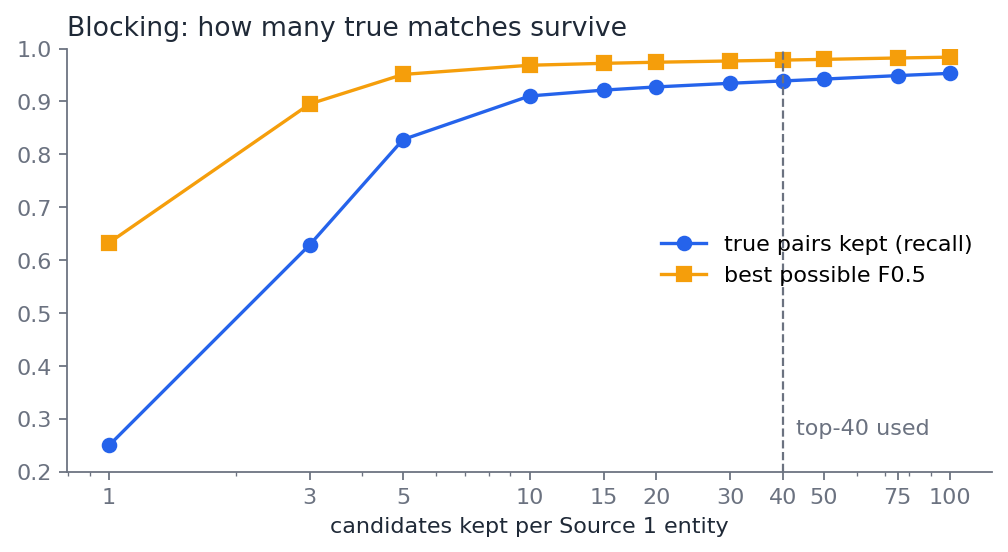

In [6]:
b = json.loads((REP / "blocking.json").read_text())
display(pd.DataFrame(b["by_top_k"]))
display(Image(str(REP / "figures" / "blocking_recall.png")))

## 5. Model and decision rule

,what,t_top,t_more,f05,precision,recall,predicted_links
0,validation (held-out businesses),0.675,0.7,0.961465,0.990527,0.913593,422129
1,perfect classifier on the same candidates,0.500,0.5,0.977512,1.000000,0.937066,429108


,t_top,t_more,f05,precision,recall,predicted_links
India,0.675,0.7,0.9448,0.9857,0.8854,164990.0
US,0.675,0.7,0.9726,0.9937,0.9325,257139.0


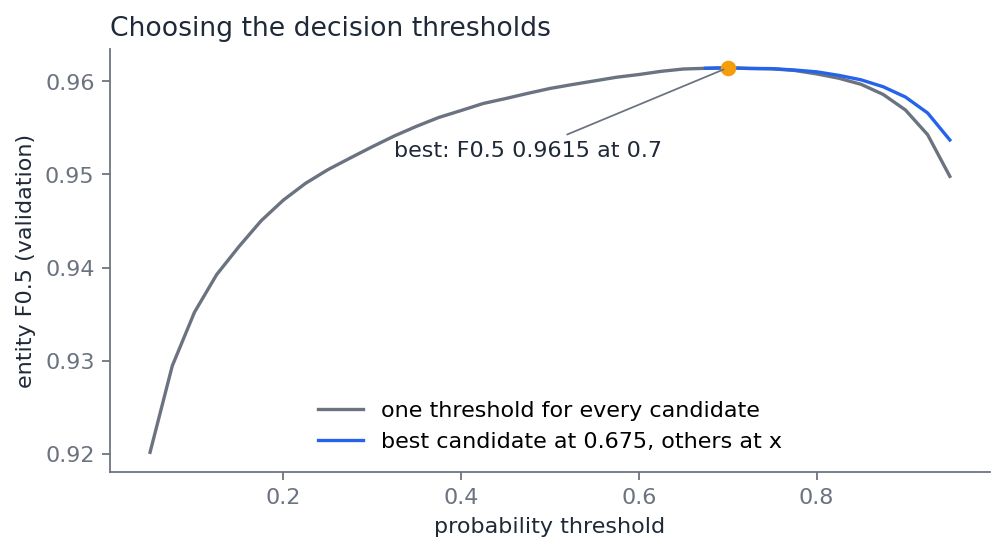

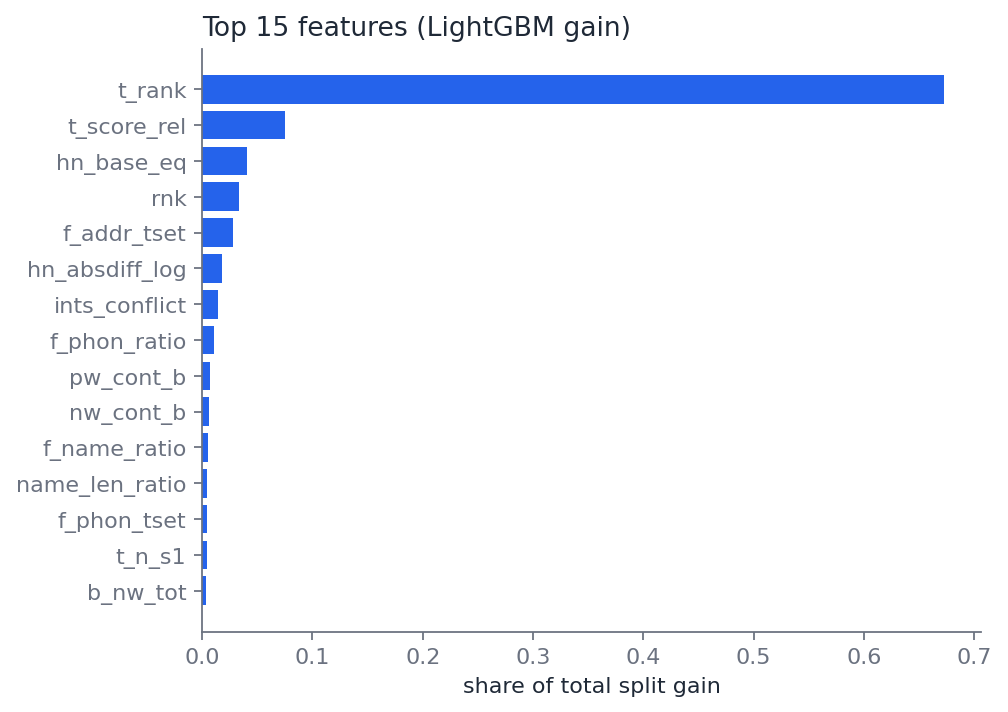

In [7]:
v = json.loads((REP / "validation.json").read_text())
display(pd.DataFrame([{"what": "validation (held-out businesses)", **v["best"]},
                      {"what": "perfect classifier on the same candidates", **v["blocking_ceiling"]}]))
display(pd.DataFrame(v["by_country"]).T)
display(Image(str(REP / "figures" / "threshold_curve.png")))
display(Image(str(REP / "figures" / "feature_importance.png")))

## 6. Where it still goes wrong

In [8]:
display(Markdown((REP / "error_analysis.md").read_text().split("## False links")[0]))

# Error analysis (validation)

Decision rule: best candidate if p >= 0.675, further candidates if p >= 0.7, each Source 2/3 record given to one Source 1 entity at most.

Correct links: 418,453. False links: 3,676. Missed links among candidates: 10,655. True links lost in blocking: 28,548.



## 7. Does it transfer to a country it has never seen?

,held out,F0.5 trained with it,F0.5 never seen
0,India,0.9403,0.8740
1,US,0.9704,0.9538


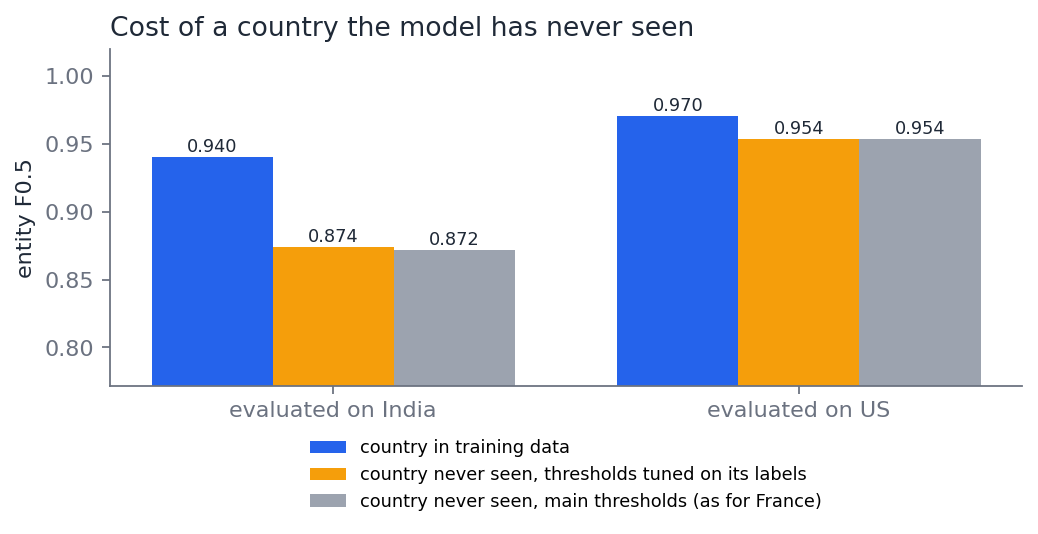

In [9]:
p = REP / "leave_one_country_out.json"
if p.exists():
    rows = json.loads(p.read_text())
    display(pd.DataFrame([{"held out": r["held_out_country"], "F0.5 trained with it": r["trained_with_it"]["f05"],
                           "F0.5 never seen": r["trained_without_it"]["f05"]} for r in rows]))
    display(Image(str(REP / "figures" / "leave_one_country_out.png")))